## NBA Assists per Minute Predictor - XGBoost Quantile
**- Owner:** Alex

**- Status:** Exploration only - not a production pipeline yet

**- Last Updated:** 10/19/26

### Question

**How accurately can we predict an NBA player's assists per minute in their next game,
and can XGBoost beat last-game assists per minute, the season-to-date average, and an EWMA of recent assists per minute?**

### Decision Criteria
**- Primary metric:** q50 pinball (assists per minute). Lower is better.

**- Secondary metric:** 80% interval (q10–q90) and 90% interval (q05–q95) coverage near their targets

**- Serving threshold:** none yet — exploration only

**- Guardrail:** no quantile crossing; 2025-26 is scored once and never used to tune

### Data Contract
**- Data:** nba_api, rotowire, and basketball reference

**- Unit:** one row per player-game (`game_id`, `player_id`)

**- Features:** `AST_FEATURES` from the assists rate model. Pregame only. Game N minutes, game N assists, game N points, and `predicted_minutes_oof` are excluded.

**- Split:** chronological; train through 2024-25, hold out 2025-26

### Setup and Configurations

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import seaborn as sns
from sklearn.metrics import mean_absolute_error, mean_squared_error
from xgboost import XGBRegressor

def _repo_root() -> Path:
    starts = []
    nb = globals().get("__vsc_ipynb_file__")
    if nb:
        starts.append(Path(nb).resolve().parent)
    starts.append(Path.cwd().resolve())
    for start in starts:
        for candidate in (start, *start.parents):
            if (candidate / "pyproject.toml").is_file():
                return candidate
    raise RuntimeError("could not find repo root (pyproject.toml)")

ROOT = _repo_root()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.features.minutes.rolling import prior_expanding, prior_shift
from src.features.assists import add_ast_rate_features

In [ ]:
# ── Prop-specific config (capped assists per minute) ─────────────────────────

HOLDOUT_SEASON = "2025-26"
ID_COLS = ["game_id", "player_id", "season_year", "player_name", "game_date"]
# Pre-holdout appearances: median 0.08, and no 10+ minute game reaches 0.72.
# 1.0 only clips short-stint ratios (about 0.04% of appearances).
RATE_CAP = 1.5
TARGET_COL = "ast_per_min"
ROLE_COL = "starting"
SEED = 42

QUANTILES = [0.05, 0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90, 0.95]

# Starting point is the points-rate search. Replace with tune_xgb_quantile
# on the train pool before treating these as an assists-specific fit.
XGB_PARAMS = dict(
    objective="reg:quantileerror",
    n_estimators=1695,
    max_depth=3,
    learning_rate=0.052852647946832816,
    subsample=0.5916232263322159,
    colsample_bytree=0.6284413523882679,
    reg_alpha=0.022871045941195746,
    reg_lambda=2.0960269065270034,
    min_child_weight=8,
    n_jobs=-1,
    random_state=42,
    early_stopping_rounds=50,
)
# Cuts follow the pre-holdout appearance distribution (p50 0.08, p75 0.15, p90 0.22).
RATE_TIERS = {
    "<0.08": lambda a: a < 0.08,
    "0.08-0.15": lambda a: (a >= 0.08) & (a < 0.15),
    "0.15-0.25": lambda a: (a >= 0.15) & (a < 0.25),
    "0.25+": lambda a: a >= 0.25,
}

ARTIFACT_STEM = "ast_nba_model"

from models.shared.splits import prepare_splits, tukey_fences
from models.shared.train import (
    evaluate_holdout,
    run_timeseries_cv,
    run_walk_forward,
)
from models.shared.analysis import run_feature_ablation, analyze_correlations
from models.shared.artifacts import save_model_bundle, load_model_bundle, predict_quantiles
from models.shared.metrics import interval_coverage, pinball_50, pinball_loss
from models.shared.oos import capped_rate


### Data

In [3]:
s20 = pd.read_parquet(ROOT / "data/silver/nba/2019-20/regular_season/player_gamelogs.parquet")
s21 = pd.read_parquet(ROOT / "data/silver/nba/2020-21/regular_season/player_gamelogs.parquet")
s22 = pd.read_parquet(ROOT / "data/silver/nba/2021-22/regular_season/player_gamelogs.parquet")
s23 = pd.read_parquet(ROOT / "data/silver/nba/2022-23/regular_season/player_gamelogs.parquet")
s24 = pd.read_parquet(ROOT / "data/silver/nba/2023-24/regular_season/player_gamelogs.parquet")
s25 = pd.read_parquet(ROOT / "data/silver/nba/2024-25/regular_season/player_gamelogs.parquet")
s26 = pd.read_parquet(ROOT / "data/silver/nba/2025-26/regular_season/player_gamelogs.parquet")
df = pd.concat([s20, s21, s22, s23, s24, s25, s26])
df['starting'] = (
    df['start_position'].astype('string').str.strip().isin(['G', 'F', 'C']).astype(int)
)
df.sample(5)

,season_year,player_id,player_name,nickname,team_id,team_abbreviation,team_name,game_id,game_date,matchup,...,opp_pace,opp_pace_per40,opp_poss,opp_pie,season_type,pos,game_total,team_spread,player_team_spread,starting
5251,2021-22,1627826,Ivica Zubac,Ivica,1610612746,LAC,LA Clippers,0022100980,2022-03-08T00:00:00,LAC @ GSW,...,101.50,84.58,101,0.576,Regular Season,C,225.0,-6.0,6.0,1
20703,2024-25,1630191,Isaiah Stewart,Isaiah,1610612765,DET,Detroit Pistons,0022400278,2024-11-25T00:00:00,DET vs. TOR,...,92.50,77.08,92,0.451,Regular Season,C,220.0,-4.0,-4.0,0
7246,2023-24,1628989,Kevin Huerter,Kevin,1610612758,SAC,Sacramento Kings,0022300862,2024-03-01T00:00:00,SAC @ MIN,...,92.83,77.36,103,0.513,Regular Season,SG,222.5,-8.0,8.0,1
9539,2023-24,202695,Kawhi Leonard,Kawhi,1610612746,LAC,LA Clippers,0022300749,2024-02-10T00:00:00,LAC vs. DET,...,103.00,85.83,103,0.481,Regular Season,SF,236.0,-17.0,-17.0,1
22277,2025-26,202691,Klay Thompson,Klay,1610612742,DAL,Dallas Mavericks,0022500238,2025-11-16T00:00:00,DAL vs. POR,...,101.43,84.53,112,0.431,Regular Season,SF,236.5,2.5,2.5,0


In [4]:
# Data Quality Checks
print(f"Number of rows : {len(df)}")
print(f"Number of columns: {len(df.columns)}")
print(f"Number of Unique Players: {df['player_id'].nunique()}")
print(f"Number of Unique Games: {df['game_id'].nunique()}")
print(f"Total number of duplicates: {df.duplicated(subset=['game_id', 'player_id']).sum()}")
print(f"Missing assists: {df['ast'].isna().sum()}")
print(f"Missing minutes: {df['minutes'].isna().sum()}")
print(f"Zero-minute rows: {int((df['minutes'] == 0).sum())}")
print(f"Median assists: {df['ast'].median()}")
print(f"Mean assists: {df['ast'].mean().round(3)}")
played = df.loc[df["minutes"] > 0, "ast"] / df.loc[df["minutes"] > 0, "minutes"]
print(f"Median assists per minute (appearances): {played.median():.3f}")
print(f"Mean assists per minute (appearances): {played.mean():.3f}")
print(f"Max raw assists per minute: {played.max():.3f}")

Number of rows : 176738
Number of columns: 190
Number of Unique Players: 1172
Number of Unique Games: 8289
Total number of duplicates: 0
Missing assists: 0
Missing minutes: 0
Zero-minute rows: 13
Median assists: 2.0
Mean assists: 2.404
Median assists per minute (appearances): 0.077
Mean assists per minute (appearances): 0.098
Max raw assists per minute: 22.222


### Features

In [5]:
# Assists-per-minute features. ast_per_min_ewm_hl_10 is prior ewm(assists) /
# prior ewm(minutes), half-life 10, computed inside add_ast_rate_features.
df = add_ast_rate_features(df)

In [6]:
# selected features to use in the model
AST_FEATURES = [
    "ast_per_min_ewm_hl_10",
    "ast_per_min_p80_10",
    "ast_per_min_p80_minus_p20_10",
    "player_ast_rate_last10",
    "player_ast_rate_season_to_date",
    "player_ast_pct_last10",
    "player_usg_pct_last10",
    "player_pass_per_min_last10",
    "player_pass_per_touch_last10",
    "player_sast_per_min_last10",
    "player_min_last5",
    "starting",
    "team_ast_pct_last10",
    "team_pace_last10",
    "opp_ast_allowed_per_100_last10",
    "opp_def_rating_last10",
    "player_team_spread",
]
_EXCLUDED_FEATURES = {"minutes", "ast", "pts", "predicted_minutes_oof"}
leaked = _EXCLUDED_FEATURES.intersection(AST_FEATURES)
if leaked:
    raise AssertionError(f"Game-N outcomes leaked into features: {sorted(leaked)}")
missing = [column for column in AST_FEATURES if column not in df.columns]
if missing:
    raise KeyError(f"Rate features missing from the panel: {missing}")
print(f"Number of features: {len(AST_FEATURES)}")
print(f"Number of nulls: {df[AST_FEATURES].isna().sum().sum()}")

Number of features: 17
Number of nulls: 30190


### Train/validation/test design
**- Train:** 2019-10-22 → 2025-04-13 (2019-20, 2020-21, 2021-22, 2022-23, 2023-24, 2024-25). Each fold fits on its past dates. The 2025-26 fit uses the first 90% of this pool.

**- Validation:** Inside the train pool only. Optuna picks hyperparameters on a 3-fold TimeSeriesSplit by q50 pinball. Walk-forward then scores 4 non-overlapping blocks, each the next 10% of game dates after a 50% training window, stepping forward 10%. Those windows end 2024-11-25, 2024-12-31, 2025-02-01, and 2025-03-10. The first half of train dates, and dates after 2025-03-10, are never scored.

**- Test:** 2025-10-21 → 2026-04-12 (2025-26). Scored once, after features and hyperparameters are locked on the validation folds.

**- Split type:** Chronological. Walk-forward keeps every row from a game_date on one side. TimeSeriesSplit cuts by row index, so one slate can straddle a fold.

**- Embargo:** None. The next game date after the last training date is validation. The gap from 2025-04-13 to 2025-10-21 is the offseason, not a purge.

**- Important:** 2025-26 is not used to choose features, hyperparameters, or early-stopping rounds. Walk-forward still early-stops on the rows it scores. The holdout fit early-stops on the last 10% of the train pool and never puts 2025-26 in eval_set.

In [ ]:
from models.shared.oos import capped_rate

df = df.loc[df["minutes"] > 0].copy()
df = df.sort_values(
    ["game_date", "game_id", "player_id"], kind="mergesort"
).reset_index(drop=True)
df[TARGET_COL] = capped_rate(df["ast"], df["minutes"], cap=RATE_CAP)
# Naive baselines for the assists-per-minute label. Not model features,
# except the EWMA, which is also in AST_FEATURES.
# Lag and season-to-date use the capped label. The EWMA was built from raw assists and minutes.
df["ast_per_min_lag_1"] = prior_shift(df, TARGET_COL, ["player_id"])
df["season_ast_per_min_mean"] = prior_expanding(
    df, TARGET_COL, ["player_id", "season_year"], "mean"
)
print(f"After filtering appearances: {len(df):,} rows")
print(df[TARGET_COL].describe().round(3))

splits = prepare_splits(
    df,
    holdout_season=HOLDOUT_SEASON,
    features=AST_FEATURES,
    target_col=TARGET_COL,
    id_cols=ID_COLS,
    role_col=ROLE_COL,
    extra_keep=[
        "minutes",
        "ast",
        "pts",
        "ast_per_min_lag_1",
        "season_ast_per_min_mean",
        "ast_per_min_ewm_hl_10",
    ],
)
rate_df = splits["ppm_df"]
rate_holdout = splits["ppm_holdout"]
X = splits["X"]
y = splits["y"]
print(f"Train pool (excl. {HOLDOUT_SEASON}) : {len(rate_df):,} rows")
print(f"Holdout   ({HOLDOUT_SEASON})        : {len(rate_holdout):,} rows")
print(
    f"Date range (train)   : {rate_df['game_date'].min().date()} → "
    f"{rate_df['game_date'].max().date()}"
)
print(
    f"Date range (holdout) : {rate_holdout['game_date'].min().date()} → "
    f"{rate_holdout['game_date'].max().date()}"
)

# Fences come from the train pool only. 2025-26 does not move the cutoff.
# Rates on the fence stay. The holdout still contains every appearance.
fence_low, fence_high = tukey_fences(rate_df[TARGET_COL])
keep = rate_df[TARGET_COL].between(fence_low, fence_high)
n_train = len(rate_df)
n_dropped = int((~keep).sum())
rate_df = rate_df.loc[keep].reset_index(drop=True)
X = rate_df[splits["features"]].copy()
y = rate_df[TARGET_COL]
print(
    f"Train Tukey fence [{fence_low:.2f}, {fence_high:.2f}]: "
    f"dropped {n_dropped:,} of {n_train:,} extreme rates "
    f"({n_dropped / n_train:.1%})"
)
print(f"Train pool after outlier drop: {len(rate_df):,} rows")
print(f"Holdout still includes every appearance: {len(rate_holdout):,} rows")

After filtering appearances: 176,725 rows
count    176725.000
mean          0.098
std           0.099
min           0.000
25%           0.000
50%           0.077
75%           0.146
max           1.000
Name: ast_per_min, dtype: float64
Train pool (excl. 2025-26) : 150,076 rows
Holdout   (2025-26)        : 26,649 rows
Date range (train)   : 2019-10-22 → 2025-04-13
Date range (holdout) : 2025-10-21 → 2026-04-12
Train pool (excl. 2025-26) : 150,076 rows
Holdout   (2025-26)        : 26,649 rows
Date range (train)   : 2019-10-22 → 2025-04-13
Date range (holdout) : 2025-10-21 → 2026-04-12
Train Tukey fence [-0.22, 0.36]: dropped 2,677 of 150,076 extreme rates (1.8%)
Train pool after outlier drop: 147,399 rows
Holdout still includes every appearance: 26,649 rows


### EDA

Appearance rows: 176,725
Features with a null: 16 / 17
Rows with any null feature: 12,376 (7.0%)


,n_missing,pct_missing
ast_per_min_p80_10,5631,3.19
ast_per_min_p80_minus_p20_10,5631,3.19
player_team_spread,4200,2.38
player_ast_rate_season_to_date,3936,2.23
player_pass_per_touch_last10,1307,0.74
ast_per_min_ewm_hl_10,1172,0.66
player_ast_rate_last10,1172,0.66
player_ast_pct_last10,1172,0.66
player_usg_pct_last10,1172,0.66
player_pass_per_min_last10,1172,0.66


,ast_per_min_p80_10,ast_per_min_p80_minus_p20_10,player_team_spread,player_ast_rate_season_to_date,player_pass_per_touch_last10,ast_per_min_ewm_hl_10,player_ast_rate_last10,player_ast_pct_last10,player_usg_pct_last10,player_pass_per_min_last10,player_sast_per_min_last10,player_min_last5,team_ast_pct_last10,team_pace_last10,opp_ast_allowed_per_100_last10,opp_def_rating_last10
season_year,,,,,,,,,,,,,,,,
2019-20,11.5,11.5,7.7,2.4,2.8,2.4,2.4,2.4,2.4,2.4,2.4,2.4,1.4,1.4,1.4,1.4
2020-21,2.3,2.3,0.0,2.3,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.0,0.0,0.0,0.0
2021-22,2.3,2.3,2.3,2.3,0.6,0.5,0.5,0.5,0.5,0.5,0.5,0.5,0.0,0.0,0.0,0.0
2022-23,1.6,1.6,0.7,2.1,0.4,0.3,0.3,0.3,0.3,0.3,0.3,0.3,0.0,0.0,0.0,0.0
2023-24,1.9,1.9,3.9,2.2,0.4,0.4,0.4,0.4,0.4,0.4,0.4,0.4,0.0,0.0,0.0,0.0
2024-25,2.0,2.0,0.2,2.2,0.4,0.4,0.4,0.4,0.4,0.4,0.4,0.4,0.0,0.0,0.0,0.0
2025-26,1.9,1.9,2.3,2.2,0.4,0.4,0.4,0.4,0.4,0.4,0.4,0.4,0.0,0.0,0.0,0.0


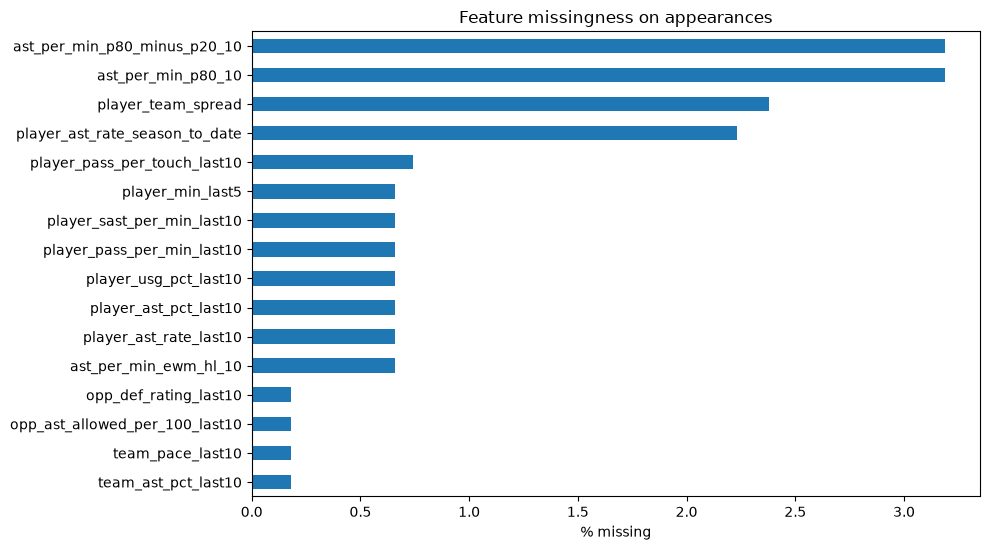

In [8]:
# Feature missingness

miss = pd.DataFrame({
    "n_missing": df[AST_FEATURES].isna().sum(),
    "pct_missing": (df[AST_FEATURES].isna().mean() * 100).round(2),
}).sort_values(["pct_missing", "n_missing"], ascending=False)

n_any = int(df[AST_FEATURES].isna().any(axis=1).sum())
print(f"Appearance rows: {len(df):,}")
print(f"Features with a null: {int((miss['n_missing'] > 0).sum())} / {len(AST_FEATURES)}")
print(f"Rows with any null feature: {n_any:,} ({n_any / len(df):.1%})")

sparse = miss.index[miss["n_missing"] > 0].tolist()
display(miss)
if sparse:
    season_miss_pct = (
        df[sparse]
        .isna()
        .groupby(df["season_year"], sort=True)
        .mean()
        .mul(100)
        .round(1)
    )
    display(season_miss_pct)
    fig, ax = plt.subplots(figsize=(10, max(3, 0.35 * len(sparse))))
    miss.loc[sparse, "pct_missing"].sort_values().plot.barh(ax=ax, color="C0")
    ax.set_xlabel("% missing")
    ax.set_title("Feature missingness on appearances")
    fig.tight_layout()
    plt.show()
else:
    print("Every selected feature is complete on this frame.")

n=176,725  min=0.00  p50=0.08  max=1.00
Tukey fence [-0.22, 0.36]  outside=3,110 (1.8%)
Rows at the 1 assists-per-minute cap: 72


,season_year,game_date,player_name,ast_per_min,starting
188,2019-20,2019-10-23,Garrison Mathews,1.0,0
4992,2019-20,2019-11-24,Chris Clemons,1.0,0
7244,2019-20,2019-12-08,Devon Hall,1.0,0
7834,2019-20,2019-12-12,Tim Frazier,1.0,0
9835,2019-20,2019-12-26,De'Aaron Fox,1.0,1
14397,2019-20,2020-01-24,Jevon Carter,1.0,0
15557,2019-20,2020-02-01,Chimezie Metu,1.0,0
16970,2019-20,2020-02-11,Johnathan Motley,1.0,0


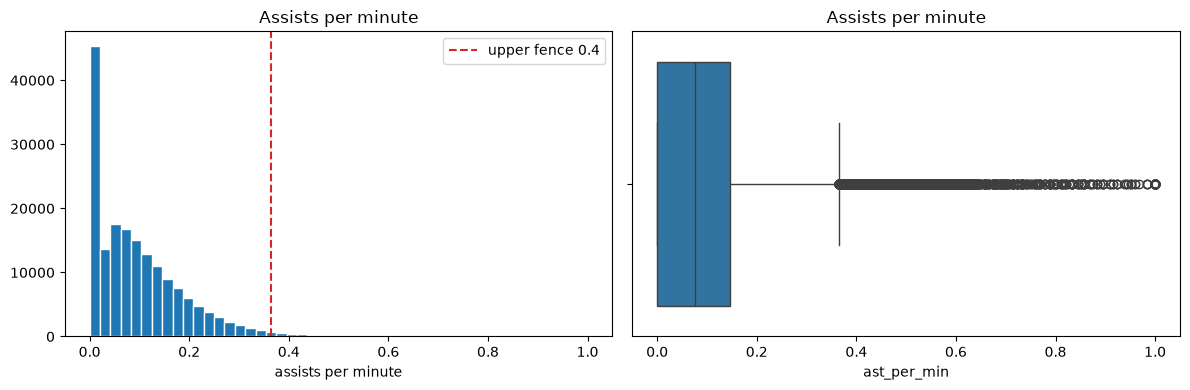

Binary inputs are omitted. A point is outside when it is past 1.5 IQR from the quartiles.


,feature,n,pct_outside,fence_low,fence_high,min,p50,max
0,ast_per_min_p80_minus_p20_10,171094,3.65,-0.02,0.21,0.00,0.09,1.06
1,player_ast_rate_season_to_date,172789,2.93,-0.06,0.24,0.00,0.08,1.62
2,player_ast_rate_last10,175553,2.75,-0.06,0.25,0.00,0.08,1.62
3,ast_per_min_ewm_hl_10,175553,2.69,-0.06,0.24,0.00,0.08,1.62
4,player_sast_per_min_last10,175553,2.66,-0.02,0.04,0.00,0.01,0.54
5,player_ast_pct_last10,175553,2.51,-0.10,0.37,0.00,0.12,1.00
6,ast_per_min_p80_10,171094,2.08,-0.07,0.34,0.00,0.13,1.06
7,player_usg_pct_last10,175553,1.41,0.03,0.33,0.00,0.18,1.00
8,player_pass_per_touch_last10,175418,1.26,0.50,0.93,0.00,0.72,1.67
9,team_ast_pct_last10,176405,0.85,0.49,0.75,0.36,0.62,0.78


In [ ]:
# Outliers

rate = df[TARGET_COL]
q1, q3 = rate.quantile(0.25), rate.quantile(0.75)
iqr = q3 - q1
lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
n_tukey = int(((rate < lo) | (rate > hi)).sum())
n_ot = int((rate >= RATE_CAP).sum())
print(
    f"n={len(rate):,}  min={rate.min():.2f}  "
    f"p50={rate.median():.2f}  max={rate.max():.2f}"
)
print(
    f"Tukey fence [{lo:.2f}, {hi:.2f}]  "
    f"outside={n_tukey:,} ({n_tukey / len(rate):.1%})"
)
print(f"Rows at the {RATE_CAP:g} assists-per-minute cap: {n_ot:,}")

top_minutes = (
    df.nlargest(8, TARGET_COL)[
        ["season_year", "game_date", "player_name", TARGET_COL, "starting"]
    ]
    .assign(game_date=lambda frame: pd.to_datetime(frame["game_date"]).dt.date)
)
display(top_minutes)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(rate, bins=48, color="C0", edgecolor="white")
axes[0].axvline(hi, color="C3", ls="--", label=f"upper fence {hi:.1f}")
axes[0].set_title("Assists per minute")
axes[0].set_xlabel("assists per minute")
axes[0].legend()
sns.boxplot(x=rate, ax=axes[1], color="C0")
axes[1].set_title("Assists per minute")
fig.tight_layout()
plt.show()

outlier_rows = []
for col in AST_FEATURES:
    values = df[col].dropna()
    if values.nunique(dropna=True) <= 2:
        continue
    fq1, fq3 = values.quantile([0.25, 0.75])
    spread = float(fq3 - fq1)
    if spread <= 0:
        continue
    fence_lo = float(fq1 - 1.5 * spread)
    fence_hi = float(fq3 + 1.5 * spread)
    outside = (values < fence_lo) | (values > fence_hi)
    outlier_rows.append({
        "feature": col,
        "n": int(values.shape[0]),
        "pct_outside": round(100 * float(outside.mean()), 2),
        "fence_low": round(fence_lo, 2),
        "fence_high": round(fence_hi, 2),
        "min": round(float(values.min()), 2),
        "p50": round(float(values.median()), 2),
        "max": round(float(values.max()), 2),
    })

feature_outliers = (
    pd.DataFrame(outlier_rows)
    .sort_values("pct_outside", ascending=False)
    .reset_index(drop=True)
)
print("Binary inputs are omitted. A point is outside when it is past 1.5 IQR from the quartiles.")
display(feature_outliers)

In [10]:
# Coverage by Season

complete = ~df[AST_FEATURES].isna().any(axis=1)
coverage = df.groupby("season_year", sort=True).agg(
    rows=("player_id", "size"),
    players=("player_id", "nunique"),
    games=("game_id", "nunique"),
    first_game=("game_date", "min"),
    last_game=("game_date", "max"),
)
coverage["first_game"] = pd.to_datetime(coverage["first_game"]).dt.date
coverage["last_game"] = pd.to_datetime(coverage["last_game"]).dt.date
coverage["pct_rows_complete"] = (
    complete.groupby(df["season_year"], sort=True).mean().mul(100).round(1)
)
coverage["mean_missing_features"] = (
    df[AST_FEATURES]
    .isna()
    .sum(axis=1)
    .groupby(df["season_year"], sort=True)
    .mean()
    .round(2)
)
print(f"Seasons: {len(coverage)}  rows: {int(coverage['rows'].sum()):,}")
display(coverage)

Seasons: 7  rows: 176,725


,rows,players,games,first_game,last_game,pct_rows_complete,mean_missing_features
season_year,,,,,,,
2019-20,22392,529,1059,2019-10-22,2020-08-14,81.2,0.58
2020-21,23054,540,1080,2020-12-22,2021-05-16,95.9,0.11
2021-22,26036,605,1230,2021-10-19,2022-04-10,93.8,0.14
2022-23,25892,539,1230,2022-10-18,2023-04-09,96.0,0.09
2023-24,26399,572,1230,2023-10-24,2024-04-14,92.5,0.13
2024-25,26303,569,1230,2024-10-22,2025-04-13,96.1,0.10
2025-26,26649,582,1230,2025-10-21,2026-04-12,94.2,0.11


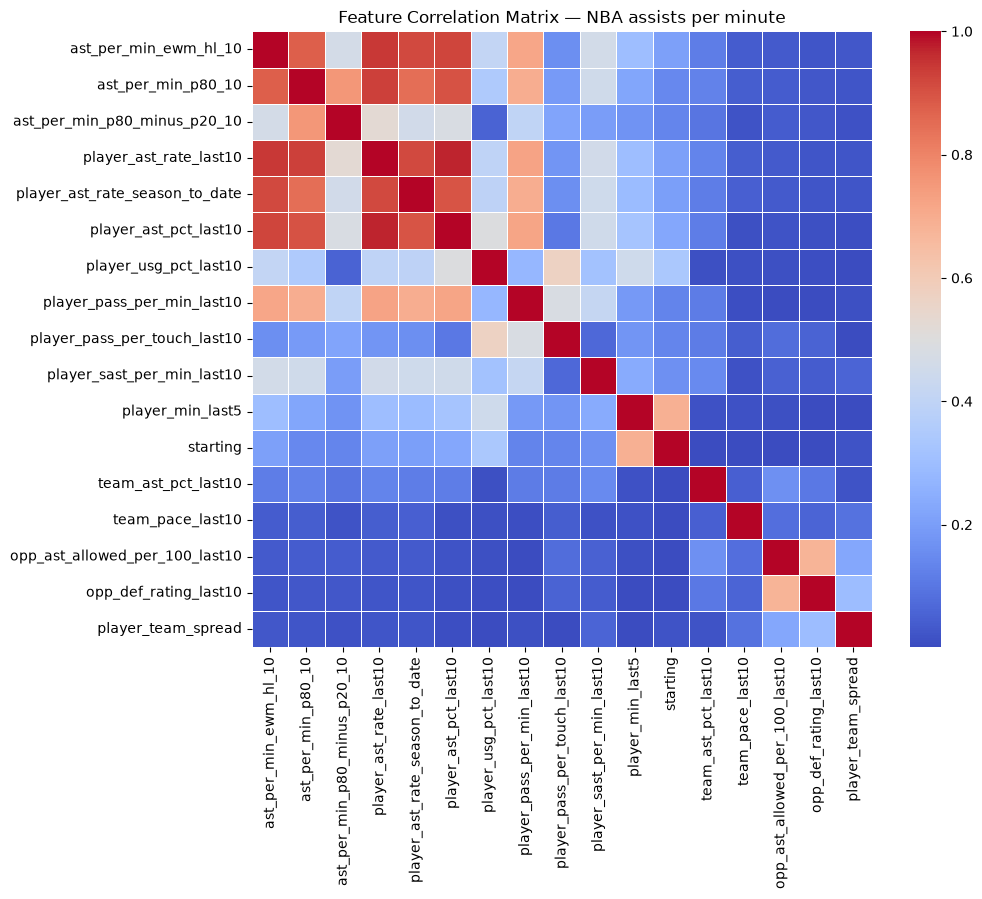

--- High Correlation Report (Threshold > 0.95) ---
player_ast_pct_last10 <-> player_ast_rate_last10: 0.9704


['player_ast_pct_last10']

In [11]:
correlated_features = analyze_correlations(
    df, AST_FEATURES, title="Feature Correlation Matrix — NBA assists per minute"
)
correlated_features

### Models

In [12]:
# Hyperparameter tuning
# Leave commented if you don't want to retune the model

# import importlib
# import models.shared.train as train

# importlib.reload(train)
# tune_xgb_quantile = train.tune_xgb_quantile

# result = tune_xgb_quantile(X, y, n_trials=50, n_splits=3)
# XGB_PARAMS = result["best_params"]

In [13]:
# XGBoost using time series cross validation and walk forward validation

tscv_results = run_timeseries_cv(
    X, y, rate_df,
    xgb_params=XGB_PARAMS,
    role_col=ROLE_COL,
    tiers=RATE_TIERS,
    quantiles=QUANTILES,
)
wf = run_walk_forward(
    X, y, rate_df,
    xgb_params=XGB_PARAMS,
    role_col=ROLE_COL,
    tiers=RATE_TIERS,
    quantiles=QUANTILES,
    n_folds=5,
)

wf_results = wf["wf_results"]
models_last = wf["models_last"]
preds_last = wf["preds_last"]
X_val_last = wf["X_val_last"]
y_val_last = wf["y_val_last"]
starting_last = wf["starting_last"]
last_fold = wf["last_fold"]

── Phase 1: TimeSeriesSplit (XGBoost) ──────────────────────────

TSCV fold 1
  n=24566
  pinball  | q0.05=0.004  q0.10=0.008  q0.20=0.014  q0.30=0.019  q0.40=0.023  q0.50=0.025  q0.60=0.025  q0.70=0.024  q0.80=0.020  q0.90=0.014  q0.95=0.008
  coverage | 80%=84.7% (target 80%)  90%=92.8% (target 90%)
  Starters   | n=11535 | pinball q50: 0.023 | 80% coverage: 83.2%
  Bench      | n=13031 | pinball q50: 0.027 | 80% coverage: 85.9%
  minute tiers by predicted q50
  <0.08      | n=15838 | pinball q50: 0.023 | 80% coverage: 87.2%
  0.08-0.15  | n= 5842 | pinball q50: 0.029 | 80% coverage: 80.3%
  0.15-0.25  | n= 2739 | pinball q50: 0.031 | 80% coverage: 79.6%
  0.25+      | n=  147 | pinball q50: 0.028 | 80% coverage: 73.5%

TSCV fold 2
  n=24566
  pinball  | q0.05=0.004  q0.10=0.008  q0.20=0.014  q0.30=0.019  q0.40=0.023  q0.50=0.025  q0.60=0.026  q0.70=0.024  q0.80=0.020  q0.90=0.013  q0.95=0.008
  coverage | 80%=84.3% (target 80%)  90%=92.9% (target 90%)
  Starters   | n=11648 | pinbal

In [14]:
def score_predictions(y_true, preds, split: str):
    """Pinball loss per quantile and central interval coverage."""
    y_true = np.asarray(y_true, dtype=float)
    pinball_rows = []
    for key, pred in preds.items():
        alpha = float(str(key).split("_", 1)[1])
        pinball_rows.append({
            "split": split,
            "quantile": alpha,
            "pinball": pinball_loss(y_true, pred, alpha),
        })
    coverage_rows = []
    for low, high, nominal in ((0.10, 0.90, 0.80), (0.05, 0.95, 0.90)):
        low_key, high_key = f"q_{low:.2f}", f"q_{high:.2f}"
        if low_key not in preds or high_key not in preds:
            continue
        coverage_rows.append({
            "split": split,
            "interval": f"{nominal:.0%}",
            "coverage": interval_coverage(y_true, preds[low_key], preds[high_key]),
            "target": nominal,
        })
    return pd.DataFrame(pinball_rows), pd.DataFrame(coverage_rows)


wf_pinball, wf_coverage = score_predictions(
    y_val_last, preds_last, last_fold["fold"]
)
display(wf_pinball.round(4))
display(wf_coverage.round(4))

,split,quantile,pinball
0,WF fold 5 (2025-01-02 → 2025-04-11),0.05,0.0045
1,WF fold 5 (2025-01-02 → 2025-04-11),0.10,0.0084
2,WF fold 5 (2025-01-02 → 2025-04-11),0.20,0.0152
3,WF fold 5 (2025-01-02 → 2025-04-11),0.30,0.0205
4,WF fold 5 (2025-01-02 → 2025-04-11),0.40,0.0242
5,WF fold 5 (2025-01-02 → 2025-04-11),0.50,0.0264
6,WF fold 5 (2025-01-02 → 2025-04-11),0.60,0.0267
7,WF fold 5 (2025-01-02 → 2025-04-11),0.70,0.0251
8,WF fold 5 (2025-01-02 → 2025-04-11),0.80,0.0211
9,WF fold 5 (2025-01-02 → 2025-04-11),0.90,0.0138


,split,interval,coverage,target
0,WF fold 5 (2025-01-02 → 2025-04-11),80%,0.8377,0.8
1,WF fold 5 (2025-01-02 → 2025-04-11),90%,0.9311,0.9


In [15]:
# Test model on holdout set

holdout = evaluate_holdout(
    rate_df,
    rate_holdout,
    features=AST_FEATURES,
    target_col=TARGET_COL,
    xgb_params=XGB_PARAMS,
    role_col=ROLE_COL,
    tiers=RATE_TIERS,
    wf_results=wf_results,
    quantiles=QUANTILES,
    fold_label=f"{HOLDOUT_SEASON} Blind Holdout",
)
models_ho = holdout["models_ho"]
preds_ho = holdout["preds_ho"]
ho_metrics = holdout["ho_metrics"]
X_ho = holdout["X_ho"]
y_ho = holdout["y_ho"]

ho_pinball, ho_coverage = score_predictions(
    y_ho, preds_ho, f"{HOLDOUT_SEASON} holdout"
)
display(ho_pinball.round(4))
display(ho_coverage.round(4))

── 2025-26 Blind Holdout ─────────────────────────────────────────────────
  Train pool: 90% rows for fit, remainder for early-stopping only; predict holdout (never in eval_set).

2025-26 Blind Holdout
  n=26649
  pinball  | q0.05=0.005  q0.10=0.009  q0.20=0.017  q0.30=0.022  q0.40=0.027  q0.50=0.029  q0.60=0.030  q0.70=0.029  q0.80=0.025  q0.90=0.017  q0.95=0.011
  coverage | 80%=81.9% (target 80%)  90%=91.0% (target 90%)
  Starters   | n=12300 | pinball q50: 0.026 | 80% coverage: 80.1%
  Bench      | n=14349 | pinball q50: 0.033 | 80% coverage: 83.5%
  minute tiers by predicted q50
  <0.08      | n=14892 | pinball q50: 0.027 | 80% coverage: 85.0%
  0.08-0.15  | n= 7643 | pinball q50: 0.030 | 80% coverage: 80.2%
  0.15-0.25  | n= 3950 | pinball q50: 0.037 | 80% coverage: 74.7%
  0.25+      | n=  164 | pinball q50: 0.043 | 80% coverage: 61.0%

───────────────────────────────────────────────────────
  Walk-forward pinball q50 (mean) : 0.026
  Holdout pinball q50             : 0.029
  Pi

,split,quantile,pinball
0,2025-26 holdout,0.05,0.0049
1,2025-26 holdout,0.10,0.0092
2,2025-26 holdout,0.20,0.0166
3,2025-26 holdout,0.30,0.0225
4,2025-26 holdout,0.40,0.0268
5,2025-26 holdout,0.50,0.0295
6,2025-26 holdout,0.60,0.0303
7,2025-26 holdout,0.70,0.0289
8,2025-26 holdout,0.80,0.0249
9,2025-26 holdout,0.90,0.0174


,split,interval,coverage,target
0,2025-26 holdout,80%,0.8193,0.8
1,2025-26 holdout,90%,0.9099,0.9


In [16]:
# empirical quantile calibration

y_true = np.asarray(y_ho, dtype=float)
calibration_rows = []
for key, pred in preds_ho.items():
    alpha = float(str(key).split("_", 1)[1])
    pred = np.asarray(pred, dtype=float)
    empirical = float(np.mean(y_true <= pred))
    calibration_rows.append({
        "quantile": alpha,
        "target": alpha,
        "empirical": empirical,
        "delta": empirical - alpha,
    })
calibration = (
    pd.DataFrame(calibration_rows)
    .sort_values("quantile")
    .reset_index(drop=True)
)

print(f"{HOLDOUT_SEASON} holdout — empirical quantile calibration")
display(calibration.round(4))

2025-26 holdout — empirical quantile calibration


,quantile,target,empirical,delta
0,0.05,0.05,0.0214,-0.0286
1,0.10,0.10,0.0612,-0.0388
2,0.20,0.20,0.1770,-0.0230
3,0.30,0.30,0.2912,-0.0088
4,0.40,0.40,0.4035,0.0035
5,0.50,0.50,0.4962,-0.0038
6,0.60,0.60,0.5911,-0.0089
7,0.70,0.70,0.6896,-0.0104
8,0.80,0.80,0.7882,-0.0118
9,0.90,0.90,0.8805,-0.0195


In [17]:
quantile_keys = sorted(
    preds_ho,
    key=lambda key: float(str(key).split("_", 1)[1]),
)
grid = np.column_stack([
    np.asarray(preds_ho[key], dtype=float) for key in quantile_keys
])
crossed = np.any(np.diff(grid, axis=1) < 0, axis=1)
n_rows = int(len(crossed))
n_crossed = int(crossed.sum())
print(
    f"{HOLDOUT_SEASON} holdout quantile crossing: "
    f"{n_crossed:,} / {n_rows:,} rows ({n_crossed / n_rows:.1%})"
)

pair_rows = []
for left, right in zip(quantile_keys, quantile_keys[1:]):
    pair_rate = float(np.mean(
        np.asarray(preds_ho[left], dtype=float)
        > np.asarray(preds_ho[right], dtype=float)
    ))
    pair_rows.append({
        "lower": left,
        "upper": right,
        "crossing_rate": pair_rate,
    })
crossing_pairs = pd.DataFrame(pair_rows)
display(crossing_pairs.round(4))

2025-26 holdout quantile crossing: 1,841 / 26,649 rows (6.9%)


,lower,upper,crossing_rate
0,q_0.05,q_0.10,0.0023
1,q_0.10,q_0.20,0.0048
2,q_0.20,q_0.30,0.0295
3,q_0.30,q_0.40,0.0291
4,q_0.40,q_0.50,0.0170
5,q_0.50,q_0.60,0.0051
6,q_0.60,q_0.70,0.0005
7,q_0.70,q_0.80,0.0000
8,q_0.80,q_0.90,0.0000
9,q_0.90,q_0.95,0.0000


In [18]:
predicted = np.asarray(preds_ho["q_0.50"], dtype=float)
y_true = np.asarray(y_ho, dtype=float)
low_80 = np.asarray(preds_ho["q_0.10"], dtype=float)
high_80 = np.asarray(preds_ho["q_0.90"], dtype=float)
low_90 = np.asarray(preds_ho["q_0.05"], dtype=float)
high_90 = np.asarray(preds_ho["q_0.95"], dtype=float)
width_80 = high_80 - low_80
width_90 = high_90 - low_90

tier_rows = []
for name, fn in RATE_TIERS.items():
    mask = np.asarray(fn(predicted), dtype=bool)
    n = int(mask.sum())
    if n == 0:
        continue
    tier_rows.append({
        "tier": name,
        "n": n,
        "share": n / len(predicted),
        "pinball_q50": pinball_loss(y_true[mask], predicted[mask], 0.50),
        "empirical_q50": float(np.mean(y_true[mask] <= predicted[mask])),
        "coverage_80": interval_coverage(y_true[mask], low_80[mask], high_80[mask]),
        "coverage_90": interval_coverage(y_true[mask], low_90[mask], high_90[mask]),
        "mean_width_80": float(np.mean(width_80[mask])),
        "mean_width_90": float(np.mean(width_90[mask])),
    })
tier_report = pd.DataFrame(tier_rows)
print(f"{HOLDOUT_SEASON} holdout — rate tiers by predicted q50")
display(tier_report.round(4))

2025-26 holdout — rate tiers by predicted q50


,tier,n,share,pinball_q50,empirical_q50,coverage_80,coverage_90,mean_width_80,mean_width_90
0,<0.08,14892,0.5588,0.0269,0.4956,0.8499,0.9359,0.1532,0.1923
1,0.08-0.15,7643,0.2868,0.0305,0.5086,0.8016,0.8979,0.1942,0.2400
2,0.15-0.25,3950,0.1482,0.0366,0.4808,0.7468,0.8443,0.2102,0.2621
3,0.25+,164,0.0062,0.0432,0.3476,0.6098,0.6890,0.1735,0.2200


In [19]:
# Holdout RMSE, CRPS, and tail calibration.
# CRPS is twice the mean pinball across the trained knots.
# Lower tail: share of outcomes at or below the knot.
# Upper tail: share of outcomes above the knot.

from models.shared.minutes_sampler import row_crps

TAIL_KNOTS = (
    ("lower", 0.05),
    ("lower", 0.10),
    ("upper", 0.90),
    ("upper", 0.95),
)


def holdout_point_distribution(name, y, preds):
    y = np.asarray(y, dtype=float)
    levels = sorted(float(str(key).split("_", 1)[1]) for key in preds)
    grid = np.column_stack(
        [np.asarray(preds[f"q_{level:.2f}"], dtype=float) for level in levels]
    )
    q50 = np.asarray(preds["q_0.50"], dtype=float)
    return {
        "model": name,
        "rmse": float(np.sqrt(mean_squared_error(y, q50))),
        "crps": float(np.mean(row_crps(y, grid, np.asarray(levels)))),
    }


def tail_calibration_rows(name, y, preds):
    y = np.asarray(y, dtype=float)
    rows = []
    for side, level in TAIL_KNOTS:
        knot = np.asarray(preds[f"q_{level:.2f}"], dtype=float)
        if side == "lower":
            nominal = level
            empirical = float(np.mean(y <= knot))
        else:
            nominal = 1.0 - level
            empirical = float(np.mean(y > knot))
        rows.append({
            "model": name,
            "side": side,
            "quantile": level,
            "nominal": nominal,
            "empirical": empirical,
            "delta": empirical - nominal,
        })
    return rows


holdout_models = (
    ("XGBoost", y_ho, preds_ho),
)
score_table = pd.DataFrame(
    [holdout_point_distribution(name, y, preds) for name, y, preds in holdout_models]
)
tail_calibration = pd.DataFrame(
    [
        row
        for name, y, preds in holdout_models
        for row in tail_calibration_rows(name, y, preds)
    ]
)

print(
    f"{HOLDOUT_SEASON} holdout — q50 RMSE and 11-knot CRPS\n"
    "  CRPS is twice the mean pinball across the trained knots"
)
display(score_table.round(4))
print(
    f"{HOLDOUT_SEASON} holdout — tail calibration\n"
    "  delta is empirical minus nominal. "
    "A positive delta means more outcomes landed in that tail than the quantile claims"
)
display(tail_calibration.round(4))

2025-26 holdout — q50 RMSE and 11-knot CRPS
  CRPS is twice the mean pinball across the trained knots


,model,rmse,crps
0,XGBoost,0.0891,0.0404


2025-26 holdout — tail calibration
  delta is empirical minus nominal. A positive delta means more outcomes landed in that tail than the quantile claims


,model,side,quantile,nominal,empirical,delta
0,XGBoost,lower,0.05,0.05,0.0214,-0.0286
1,XGBoost,lower,0.10,0.10,0.0612,-0.0388
2,XGBoost,upper,0.90,0.10,0.1195,0.0195
3,XGBoost,upper,0.95,0.05,0.0686,0.0186


In [20]:
def interval_sharpness(y_true, preds):
    y_true = np.asarray(y_true, dtype=float)
    rows = []
    for low, high, nominal in ((0.10, 0.90, 0.80), (0.05, 0.95, 0.90)):
        low_key, high_key = f"q_{low:.2f}", f"q_{high:.2f}"
        width = (
            np.asarray(preds[high_key], dtype=float)
            - np.asarray(preds[low_key], dtype=float)
        )
        rows.append({
            "interval": f"{nominal:.0%}",
            "coverage": interval_coverage(y_true, preds[low_key], preds[high_key]),
            "target": nominal,
            "mean_width": float(np.mean(width)),
            "median_width": float(np.median(width)),
        })
    return pd.DataFrame(rows)

sharp_xgb = interval_sharpness(y_ho, preds_ho)

print(f"{HOLDOUT_SEASON} holdout — interval sharpness (assists per minute)")
display(sharp_xgb.round(4))

2025-26 holdout — interval sharpness (assists per minute)


,interval,coverage,target,mean_width,median_width
0,80%,0.8193,0.8,0.1735,0.1695
1,90%,0.9099,0.9,0.2165,0.2162


### Baseline

In [21]:
N_BOOT = 2_000
SEED = 42
WIS_INTERVALS = (
    (0.80, "q_0.40", "q_0.60"),
    (0.60, "q_0.30", "q_0.70"),
    (0.40, "q_0.20", "q_0.80"),
    (0.20, "q_0.10", "q_0.90"),
    (0.10, "q_0.05", "q_0.95"),
)

XGB_NAME = "Quantile XGBoost"

y_all = np.asarray(y_ho, dtype=float)
model_quantiles = {
    XGB_NAME: {key: np.asarray(pred, dtype=float) for key, pred in preds_ho.items()},
}
for name, qmap in model_quantiles.items():
    if len(next(iter(qmap.values()))) != len(y_all):
        raise ValueError(f"{name} predictions do not match the holdout length")
alpha_of = {
    key: float(str(key).split("_", 1)[1]) for key in model_quantiles[XGB_NAME]
}
ordered_keys = sorted(model_quantiles[XGB_NAME], key=alpha_of.get)
baselines = {
    "Last-game rate": rate_holdout["ast_per_min_lag_1"].to_numpy(dtype=float),
    "Season-to-date rate": rate_holdout["season_ast_per_min_mean"].to_numpy(dtype=float),
    "EWMA rate": rate_holdout["ast_per_min_ewm_hl_10"].to_numpy(dtype=float),
}
paired = np.isfinite(y_all)
for qmap in model_quantiles.values():
    paired &= np.isfinite(qmap["q_0.50"])
for pred in baselines.values():
    paired &= np.isfinite(pred)

def point_row(name, y, pred):
    error = y - pred
    absolute = np.abs(error)
    return {
        "model": name,
        "mae": float(absolute.mean()),
        "median_ae": float(np.median(absolute)),
        "mean_bias": float(error.mean()),
    }

def interval_score(y, lower, upper, alpha):
    width = upper - lower
    below = y < lower
    above = y > upper
    return (
        width
        + (2.0 / alpha) * (lower - y) * below
        + (2.0 / alpha) * (y - upper) * above
    )

def wis_values(y, qmap):
    present = [
        (alpha, qmap[low], qmap[high])
        for alpha, low, high in WIS_INTERVALS
        if low in qmap and high in qmap
    ]
    total = 0.5 * np.abs(y - qmap["q_0.50"])
    for alpha, lower, upper in present:
        total = total + (alpha / 2.0) * interval_score(y, lower, upper, alpha)
    return total / (len(present) + 0.5)

def clustered_mae_bootstrap(y, predictors, dates, n_boot, seed):
    codes, _ = pd.factorize(dates, sort=False)
    n_clusters = int(codes.max()) + 1
    cluster_n = np.bincount(codes).astype(float)
    cluster_sum = {
        name: np.bincount(codes, weights=np.abs(y - pred))
        for name, pred in predictors.items()
    }
    rng = np.random.default_rng(seed)
    draws = rng.integers(0, n_clusters, size=(n_boot, n_clusters))
    weights = np.zeros((n_boot, n_clusters), dtype=np.int32)
    np.add.at(
        weights,
        (np.repeat(np.arange(n_boot), n_clusters), draws.ravel()),
        1,
    )
    denom = weights @ cluster_n
    return {name: (weights @ total) / denom for name, total in cluster_sum.items()}

y_paired = y_all[paired]
xgb_q50_name = f"{XGB_NAME} q50"
paired_preds = {
    xgb_q50_name: model_quantiles[XGB_NAME]["q_0.50"][paired],
}
paired_preds.update({name: pred[paired] for name, pred in baselines.items()})
dates_paired = pd.to_datetime(rate_holdout["game_date"]).to_numpy()[paired]
boot_mae = clustered_mae_bootstrap(
    y_paired, paired_preds, dates_paired, N_BOOT, SEED
)

point_order = [
    "Last-game rate",
    "Season-to-date rate",
    "EWMA rate",
    xgb_q50_name,
]
point_table = pd.DataFrame([
    point_row(name, y_paired, paired_preds[name]) for name in point_order
])
best_name = min(baselines, key=lambda name: point_table.loc[
    point_table["model"] == name, "mae"
].iloc[0])
model_boot = boot_mae[xgb_q50_name]
delta_table = pd.DataFrame([
    {
        "comparison": f"XGBoost q50 − {name}",
        "delta_mae": float(
            point_table.loc[point_table["model"] == xgb_q50_name, "mae"].iloc[0]
            - point_table.loc[point_table["model"] == name, "mae"].iloc[0]
        ),
        "ci_low": float(np.quantile(model_boot - boot_mae[name], 0.025)),
        "ci_high": float(np.quantile(model_boot - boot_mae[name], 0.975)),
    }
    for name in point_order[:-1]
])

fold_rows = []
for fold in wf_results:
    part = rate_df.loc[fold["val_mask"]]
    y_fold = part[TARGET_COL].to_numpy(dtype=float)
    fold_row = {
        "fold": fold["fold"],
        "n": int(len(part)),
        "model_mae": 2.0 * float(fold["pinball"]),
    }
    for name, column in (
        ("last_game", "ast_per_min_lag_1"),
        ("season_average", "season_ast_per_min_mean"),
        ("ewma", "ast_per_min_ewm_hl_10"),
    ):
        pred = part[column].to_numpy(dtype=float)
        ok = np.isfinite(y_fold) & np.isfinite(pred)
        fold_row[name] = float(np.mean(np.abs(y_fold[ok] - pred[ok])))
    fold_row["best_baseline"] = min(
        fold_row["last_game"], fold_row["season_average"], fold_row["ewma"]
    )
    fold_row["model_minus_best"] = fold_row["model_mae"] - fold_row["best_baseline"]
    fold_rows.append(fold_row)
fold_table = pd.DataFrame(fold_rows)

print("1. Point accuracy versus baselines")
print(
    f"Identical holdout rows: {int(paired.sum()):,}  |  "
    f"dropped {int((~paired).sum()):,} with a missing baseline  |  "
    f"{N_BOOT:,} date-clustered resamples"
)
print(
    "Mean bias is actual minus predicted. "
    f"XGBoost q50 pinball {pinball_loss(y_paired, paired_preds[xgb_q50_name], 0.50):.4f}. "
    "That equals half the q50 MAE."
)
display(point_table.round(3))
print("Paired MAE difference, clustered by game date. Negative means XGBoost q50 is lower.")
display(delta_table.round(3))
print(
    "Walk-forward MAE is 2 × q50 pinball on every validation row. "
    "Baseline MAE drops rows with no prior."
)
display(fold_table.round(3))

def interval_stats(y, qmap, low, high):
    low_key, high_key = f"q_{low:.2f}", f"q_{high:.2f}"
    if low_key not in qmap or high_key not in qmap:
        return {"cov": np.nan, "width_mean": np.nan, "width_median": np.nan}
    width = qmap[high_key] - qmap[low_key]
    return {
        "cov": interval_coverage(y, qmap[low_key], qmap[high_key]),
        "width_mean": float(np.mean(width)),
        "width_median": float(np.median(width)),
    }

def distribution_row(name, y, qmap):
    band_80 = interval_stats(y, qmap, 0.10, 0.90)
    band_90 = interval_stats(y, qmap, 0.05, 0.95)
    keys = sorted(qmap, key=lambda key: float(str(key).split("_", 1)[1]))
    grid = np.column_stack([qmap[key] for key in keys])
    if grid.shape[1] < 2:
        crossed = 0.0
    else:
        crossed = float(np.mean(np.any(np.diff(grid, axis=1) < 0, axis=1)))
    return {
        "model": name,
        "cov_80": band_80["cov"],
        "width_80_mean": band_80["width_mean"],
        "width_80_median": band_80["width_median"],
        "cov_90": band_90["cov"],
        "width_90_mean": band_90["width_mean"],
        "width_90_median": band_90["width_median"],
        "wis": float(np.mean(wis_values(y, qmap))),
        "quantile_crossing": crossed,
    }

print("\n2. Distribution quality")
wis_knots = [
    f"{low}–{high}"
    for _alpha, low, high in WIS_INTERVALS
    if low in model_quantiles[XGB_NAME] and high in model_quantiles[XGB_NAME]
]
print(
    "WIS uses the trained knots only: "
    + (", ".join(wis_knots) if wis_knots else "median only")
    + ", plus the q50 term."
)
distribution = pd.DataFrame([
    distribution_row(name, y_all, qmap) for name, qmap in model_quantiles.items()
])
display(distribution.round(4))
xgb_dist = distribution.loc[distribution["model"] == XGB_NAME].iloc[0]
print(
    f"Best baseline MAE {point_table.loc[point_table['model'] == best_name, 'mae'].iloc[0]:.3f} "
    f"({best_name}) is that point forecast's CRPS."
)

print("\n3. Calibration of every quantile")
calibration = pd.DataFrame([
    {
        "model": name,
        "quantile": f"q{alpha_of[key] * 100:02.0f}",
        "expected": alpha_of[key],
        "observed": float(np.mean(y_all <= qmap[key])),
        "difference": float(np.mean(y_all <= qmap[key]) - alpha_of[key]),
    }
    for name, qmap in model_quantiles.items()
    for key in sorted(qmap, key=lambda key: float(str(key).split("_", 1)[1]))
])
display(calibration.round(4))

def subgroup_rows_for(group, mask):
    rows = []
    base = np.asarray(mask, dtype=bool) & np.isfinite(y_all)
    for name, qmap in model_quantiles.items():
        use = base & np.isfinite(qmap["q_0.50"])
        n = int(use.sum())
        if n == 0:
            continue
        y = y_all[use]
        part = {key: values[use] for key, values in qmap.items()}
        error = y - part["q_0.50"]
        band_80 = interval_stats(y, part, 0.10, 0.90)
        band_90 = interval_stats(y, part, 0.05, 0.95)
        rows.append({
            "model": name,
            "group": group,
            "n": n,
            "mae": float(np.mean(np.abs(error))),
            "bias": float(np.mean(error)),
            "wis": float(np.mean(wis_values(y, part))),
            "cov_80": band_80["cov"],
            "width_80_mean": band_80["width_mean"],
            "width_80_median": band_80["width_median"],
            "cov_90": band_90["cov"],
            "width_90_mean": band_90["width_mean"],
            "width_90_median": band_90["width_median"],
        })
    return rows

print("\n4. Pregame-defined subgroups")
print("Rate tiers use predicted q50.")
starting = rate_holdout["starting"].to_numpy()
months = pd.to_datetime(rate_holdout["game_date"]).dt.to_period("M").astype(str)
xgb_q50 = model_quantiles[XGB_NAME]["q_0.50"]
subgroup_rows = []
subgroup_rows.extend(subgroup_rows_for("Confirmed starter", starting == 1))
subgroup_rows.extend(subgroup_rows_for("Bench", starting == 0))
for name, fn in RATE_TIERS.items():
    subgroup_rows.extend(subgroup_rows_for(f"Predicted q50 {name}", fn(xgb_q50)))
for month in sorted(months.unique()):
    subgroup_rows.extend(subgroup_rows_for(str(month), months.to_numpy() == month))
subgroup_table = pd.DataFrame(subgroup_rows)
display(subgroup_table.round(3))

print("\n5. Tail failures")
tail_rows = []
for name, qmap in model_quantiles.items():
    absolute_error = np.abs(y_all - qmap["q_0.50"])
    for cutoff in (0.05, 0.10, 0.15):
        tail_rows.append({
            "model": name,
            "threshold": f">{cutoff:g} ast/min",
            "rate": float(np.mean(absolute_error > cutoff)),
            "n": int(np.sum(absolute_error > cutoff)),
        })
tail_table = pd.DataFrame(tail_rows)
display(tail_table.round(4))

xgb_cal = calibration.loc[calibration["model"] == XGB_NAME]
best_delta = delta_table.loc[
    delta_table["comparison"] == f"XGBoost q50 − {best_name}"
].iloc[0]
best_mae = float(point_table.loc[point_table["model"] == best_name, "mae"].iloc[0])
print("\nChecks from this frame")
q50_rate = float(xgb_cal.loc[xgb_cal["quantile"] == "q50", "observed"].iloc[0])
max_gap = float(xgb_cal["difference"].abs().max())
print(f"  {XGB_NAME} q50 observed rate {q50_rate:.1%}  (target about 48–52%)")
print(f"  {XGB_NAME} largest |quantile gap| {max_gap:.1%}")
print(
    f"  XGBoost q50 vs {best_name}: delta MAE {best_delta['delta_mae']:+.3f} "
    f"[{best_delta['ci_low']:+.3f}, {best_delta['ci_high']:+.3f}]"
)
print(
    f"  WIS {xgb_dist['wis']:.3f} (XGBoost) "
    f"vs best baseline CRPS/MAE {best_mae:.3f}"
)
print(
    "  walk-forward folds with XGBoost MAE below the best baseline: "
    f"{int((fold_table['model_minus_best'] < 0).sum())} / {len(fold_table)}"
)
print(
    f"  raw quantile crossing {xgb_dist['quantile_crossing']:.2%}"
)

1. Point accuracy versus baselines
Identical holdout rows: 26,067  |  dropped 582 with a missing baseline  |  2,000 date-clustered resamples
Mean bias is actual minus predicted. XGBoost q50 pinball 0.0293. That equals half the q50 MAE.


,model,mae,median_ae,mean_bias
0,Last-game rate,0.079,0.058,0.000
1,Season-to-date rate,0.062,0.048,0.002
2,EWMA rate,0.062,0.049,-0.000
3,Quantile XGBoost q50,0.059,0.042,0.018


Paired MAE difference, clustered by game date. Negative means XGBoost q50 is lower.


,comparison,delta_mae,ci_low,ci_high
0,XGBoost q50 − Last-game rate,-0.021,-0.021,-0.020
1,XGBoost q50 − Season-to-date rate,-0.004,-0.004,-0.003
2,XGBoost q50 − EWMA rate,-0.003,-0.003,-0.003


Walk-forward MAE is 2 × q50 pinball on every validation row. Baseline MAE drops rows with no prior.


...


4. Pregame-defined subgroups
Rate tiers use predicted q50.


,model,group,n,mae,bias,wis,cov_80,width_80_mean,width_80_median,cov_90,width_90_mean,width_90_median
0,Quantile XGBoost,Confirmed starter,12300,0.052,0.008,0.035,0.801,0.164,0.167,0.903,0.205,0.212
1,Quantile XGBoost,Bench,14349,0.065,0.027,0.045,0.835,0.182,0.172,0.916,0.227,0.220
2,Quantile XGBoost,Predicted q50 <0.08,14892,0.054,0.025,0.037,0.850,0.153,0.148,0.936,0.192,0.188
3,Quantile XGBoost,Predicted q50 0.08-0.15,7643,0.061,0.009,0.042,0.802,0.194,0.188,0.898,0.240,0.236
4,Quantile XGBoost,Predicted q50 0.15-0.25,3950,0.073,0.012,0.051,0.747,0.210,0.197,0.844,0.262,0.249
5,Quantile XGBoost,Predicted q50 0.25+,164,0.086,0.033,0.064,0.610,0.174,0.172,0.689,0.220,0.217
6,Quantile XGBoost,2025-10,1791,0.058,0.018,0.040,0.824,0.173,0.172,0.911,0.217,0.219
7,Quantile XGBoost,2025-11,4784,0.059,0.020,0.041,0.823,0.174,0.169,0.912,0.217,0.216
8,Quantile XGBoost,2025-12,4265,0.058,0.016,0.039,0.824,0.173,0.168,0.914,0.215,0.214
9,Quantile XGBoost,2026-01,4988,0.058,0.018,0.039,0.826,0.172,0.169,0.915,0.214,0.214



5. Tail failures


,model,threshold,rate,n
0,Quantile XGBoost,>0.05 ast/min,0.4267,11372
1,Quantile XGBoost,>0.1 ast/min,0.1597,4255
2,Quantile XGBoost,>0.15 ast/min,0.0682,1817



Checks from this frame
  Quantile XGBoost q50 observed rate 49.6%  (target about 48–52%)
  Quantile XGBoost largest |quantile gap| 3.9%
  XGBoost q50 vs EWMA rate: delta MAE -0.003 [-0.003, -0.003]
  WIS 0.040 (XGBoost) vs best baseline CRPS/MAE 0.062
  walk-forward folds with XGBoost MAE below the best baseline: 5 / 5
  raw quantile crossing 6.91%


### Features Analysis

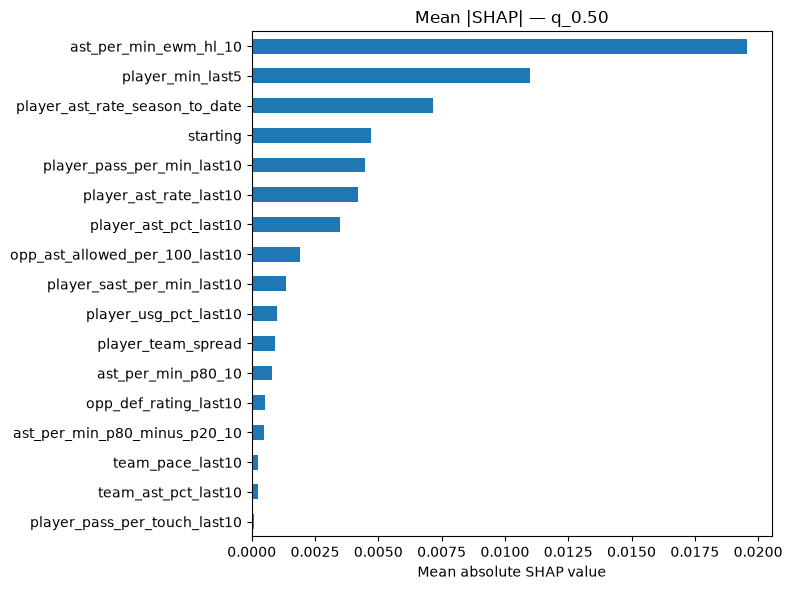

In [22]:
import shap

model = models_last["q_0.50"]
explainer = shap.TreeExplainer(model)
shap_values = explainer(X_val_last)

mean_abs_shap = np.abs(shap_values.values).mean(axis=0)
feat_imp = pd.Series(mean_abs_shap, index=AST_FEATURES).sort_values(ascending=True)

ax = feat_imp.plot(kind="barh", figsize=(8, 6))
ax.set_title("Mean |SHAP| — q_0.50")
ax.set_xlabel("Mean absolute SHAP value")
plt.tight_layout()
plt.show()

In [23]:
from sklearn.inspection import permutation_importance
from sklearn.metrics import make_scorer
from scipy import stats as sp_stats

result = permutation_importance(
    models_last["q_0.50"],
    X_val_last,
    y_val_last,
    n_repeats=30,
    random_state=42,
    scoring=make_scorer(pinball_50),
)

pi_df = (
    pd.DataFrame({
        "feature": X_val_last.columns,
        "importance": result.importances_mean,
        "std": result.importances_std,
    })
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)
pi_df.index += 1
pi_df["importance"] = pi_df["importance"].round(5)
pi_df["std"] = pi_df["std"].round(5)
pi_df["p_value"] = sp_stats.ttest_1samp(result.importances, 0.0, axis=1).pvalue.round(4)
pi_df["significant"] = pi_df["p_value"] < 0.05

print("Permutation importance (val set) — higher = more important, significant = p<0.05")
print(pi_df.to_string())

Permutation importance (val set) — higher = more important, significant = p<0.05
                           feature  importance      std  p_value  significant
1            ast_per_min_ewm_hl_10     0.00240  0.00007   0.0000         True
2                 player_min_last5     0.00161  0.00007   0.0000         True
3   player_ast_rate_season_to_date     0.00042  0.00003   0.0000         True
4                         starting     0.00032  0.00003   0.0000         True
5       player_pass_per_min_last10     0.00016  0.00002   0.0000         True
6           player_ast_rate_last10     0.00010  0.00002   0.0000         True
7            player_ast_pct_last10     0.00007  0.00002   0.0000         True
8   opp_ast_allowed_per_100_last10     0.00007  0.00001   0.0000         True
9               ast_per_min_p80_10     0.00003  0.00001   0.8869        False
10    ast_per_min_p80_minus_p20_10     0.00003  0.00000   0.0000         True
11              player_team_spread     0.00003  0.00001   0.0

In [24]:
train_mask_last = last_fold["train_mask"]
val_mask_last = last_fold["val_mask"]
X_tr_last = X.loc[train_mask_last]
X_va_last = X.loc[val_mask_last]
y_tr_last = rate_df.loc[train_mask_last, TARGET_COL]
y_va_last = rate_df.loc[val_mask_last, TARGET_COL]

ablation_df = run_feature_ablation(
    AST_FEATURES, X_tr_last, y_tr_last, X_va_last, y_va_last,
    xgb_params=XGB_PARAMS,
)

Baseline pinball q50 (all features): 0.0263
                           feature  ablated_pinball  delta_pinball
1                 player_min_last5           0.0267         0.0004
2            ast_per_min_ewm_hl_10           0.0264         0.0001
3                         starting           0.0264         0.0001
4       player_sast_per_min_last10           0.0263        -0.0000
5            opp_def_rating_last10           0.0264         0.0000
6   opp_ast_allowed_per_100_last10           0.0264         0.0000
7                 team_pace_last10           0.0263        -0.0000
8              team_ast_pct_last10           0.0263         0.0000
9     player_pass_per_touch_last10           0.0263        -0.0000
10              ast_per_min_p80_10           0.0263        -0.0000
11      player_pass_per_min_last10           0.0263        -0.0000
12           player_usg_pct_last10           0.0263        -0.0000
13           player_ast_pct_last10           0.0263        -0.0000
14  player_ast_rat

In [25]:
from scipy import stats

model = models_last["q_0.50"]
_shap_expl = shap.TreeExplainer(model, model_output="raw")
_shap_vals = _shap_expl(X_val_last)
_mean_abs_shap = np.abs(_shap_vals.values).mean(axis=0)

shap_table = pd.DataFrame({
    "feature": X_val_last.columns,
    "mean_abs_shap": _mean_abs_shap,
}).assign(shap_rank=lambda d: d["mean_abs_shap"].rank(method="min", ascending=False).astype(int))

perm_table = (
    pi_df.sort_values("importance", ascending=False)
    .reset_index(drop=True)
    .rename(columns={"importance": "perm_importance", "std": "perm_importance_std"})
)
perm_table["perm_rank"] = np.arange(1, len(perm_table) + 1)
perm_table = perm_table[["feature", "perm_rank", "perm_importance", "perm_importance_std"]]

perm_pv = pd.DataFrame({
    "feature": X_val_last.columns,
    "perm_pvalue": stats.ttest_1samp(result.importances, 0.0, axis=1, nan_policy="omit").pvalue,
})

abla = ablation_df[["feature", "delta_pinball"]].rename(columns={"delta_pinball": "ablation_delta"})

feature_audit = (
    pd.DataFrame({"feature": AST_FEATURES})
    .merge(shap_table, on="feature", how="left")
    .merge(perm_table, on="feature", how="left")
    .merge(perm_pv, on="feature", how="left")
    .merge(abla, on="feature", how="left")
)

_ms = feature_audit["mean_abs_shap"].astype(float)
_mp = feature_audit["perm_importance"].astype(float)
_max_shap = _ms.fillna(0).max()
_max_perm = _mp.fillna(0).max()
feature_audit["shap_norm"] = np.where(_max_shap > 0, _ms.fillna(0) / _max_shap, 0.0)
feature_audit["perm_norm"] = np.where(_max_perm > 0, _mp.fillna(0) / _max_perm, 0.0)
feature_audit["consensus"] = (feature_audit["shap_norm"] + feature_audit["perm_norm"]) / 2
feature_audit = feature_audit.sort_values("consensus", ascending=False).reset_index(drop=True)
feature_audit.index += 1
feature_audit["keep"] = (feature_audit["perm_pvalue"] < 0.05) & (feature_audit["ablation_delta"] > 0)

print(feature_audit.to_string())

                           feature  mean_abs_shap  shap_rank  perm_rank  perm_importance  perm_importance_std   perm_pvalue  ablation_delta  shap_norm  perm_norm  consensus   keep
1            ast_per_min_ewm_hl_10       0.019571          1          1          0.00240              0.00007  7.902245e-47          0.0001   1.000000   1.000000   1.000000   True
2                 player_min_last5       0.011004          2          2          0.00161              0.00007  5.937917e-42          0.0004   0.562249   0.670833   0.616541   True
3   player_ast_rate_season_to_date       0.007154          3          3          0.00042              0.00003  3.463074e-33          0.0000   0.365567   0.175000   0.270283  False
4                         starting       0.004727          4          4          0.00032              0.00003  1.050936e-30          0.0001   0.241515   0.133333   0.187424   True
5       player_pass_per_min_last10       0.004477          5          5          0.00016            

### Slice Analysis

In [26]:
import importlib

import models.shared.artifacts as artifact_mod

importlib.reload(artifact_mod)
from models.shared.artifacts import monotonize_quantiles

dates = pd.to_datetime(rate_holdout["game_date"])
y_all = np.asarray(y_ho, dtype=float)
raw_q = {key: np.asarray(pred, dtype=float) for key, pred in preds_ho.items()}
model = raw_q["q_0.50"]

def slice_score(name, mask, qmap):
    mask = np.asarray(mask, dtype=bool)
    n = int(mask.sum())
    if n == 0:
        return {"slice": name, "n": 0}
    y = y_all[mask]
    qmap = {key: values[mask] for key, values in qmap.items()}
    error = y - qmap["q_0.50"]
    return {
        "slice": name,
        "n": n,
        "mae": float(np.mean(np.abs(error))),
        "bias": float(np.mean(error)),
        "p_actual_le_q50": float(np.mean(y <= qmap["q_0.50"])),
        "cov_80": interval_coverage(y, qmap["q_0.10"], qmap["q_0.90"]),
        "mean_width_80": float(np.mean(qmap["q_0.90"] - qmap["q_0.10"])),
        "wis": float(np.mean(wis_values(y, qmap))),
    }

print("1. April is late regular season, not the postseason")
holdout_season = df.loc[df["season_year"].astype("string").eq(str(HOLDOUT_SEASON))]
print(holdout_season["season_type"].astype("string").value_counts(dropna=False).to_string())
print(
    f"Holdout dates {dates.min().date()} \u2192 {dates.max().date()}. "
    "The silver store only has regular_season gamelogs, so playoff games are not in this test."
)
blocks = {
    "October\u2013February": dates < "2026-03-01",
    "March 1\u201314": (dates >= "2026-03-01") & (dates < "2026-03-15"),
    "March 15\u201331": (dates >= "2026-03-15") & (dates < "2026-04-01"),
    "April regular season": dates >= "2026-04-01",
}
calendar = pd.DataFrame([slice_score(name, mask, raw_q) for name, mask in blocks.items()])
display(calendar.round(3))
print(
    "Limitation: April's higher MAE and lower 80% coverage is the last two weeks of the "
    "regular season. It is not a postseason effect, and the model has not been tested on playoff games."
)

print("\n2. Starter and bench mean bias versus median calibration")
starting = rate_holdout["starting"].to_numpy()
role = pd.DataFrame([
    slice_score("Confirmed starter", starting == 1, raw_q),
    slice_score("Bench", starting == 0, raw_q),
])
display(role.round(3))
for _, row in role.iterrows():
    if row["n"] == 0:
        continue
    gap = row["p_actual_le_q50"] - 0.50
    if abs(gap) <= 0.02:
        reading = "q50 is near 50%, so the mean bias is skew around a calibrated median"
    elif gap > 0:
        reading = "q50 is too high: actuals fall under the median more often than 50%"
    else:
        reading = "q50 is too low: actuals fall under the median less often than 50%"
    print(
        f"  {row['slice']}: bias {row['bias']:+.3f} ast/min, "
        f"P(actual <= q50) {row['p_actual_le_q50']:.1%}. {reading}."
    )

print("\n3. Monotone rearrangement")
ordered_keys = sorted(raw_q, key=lambda key: float(str(key).split("_", 1)[1]))
grid = np.column_stack([raw_q[key] for key in ordered_keys])
crossed = np.any(np.diff(grid, axis=1) < 0, axis=1)
preds_ho_mono = monotonize_quantiles(raw_q)
mono_grid = np.column_stack([preds_ho_mono[key] for key in ordered_keys])
shift = pd.DataFrame([
    {
        "quantile": key,
        "mean_abs_shift": float(np.mean(np.abs(preds_ho_mono[key] - raw_q[key]))),
        "share_changed": float(np.mean(preds_ho_mono[key] != raw_q[key])),
    }
    for key in ordered_keys
])
print(
    f"Crossing before {crossed.mean():.2%} of rows; "
    f"after rearrangement {np.any(np.diff(mono_grid, axis=1) < 0, axis=1).mean():.2%}."
)
display(shift.round(4))
print("Simulate from preds_ho_mono. The saved trees stay raw; sort each row after predict.")

print("\n4. Cold-start and missing-baseline rows")
lag = rate_holdout["ast_per_min_lag_1"].to_numpy(dtype=float)
season_avg = rate_holdout["season_ast_per_min_mean"].to_numpy(dtype=float)
ewma = rate_holdout["ast_per_min_ewm_hl_10"].to_numpy(dtype=float)
cold = ~np.isfinite(lag)
season_opener = np.isfinite(lag) & ~np.isfinite(season_avg)
missing_any = cold | season_opener | ~np.isfinite(ewma)
print(
    f"Missing any baseline: {int(missing_any.sum()):,} | "
    f"no prior game (ast_per_min_lag_1 missing): {int(cold.sum()):,} | "
    f"season opener with history: {int(season_opener.sum()):,}"
)

role_quantiles = {}
for role_value, role_name in ((1, "starter"), (0, "bench")):
    history = rate_df.loc[rate_df["starting"] == role_value, TARGET_COL].to_numpy(dtype=float)
    history = history[np.isfinite(history)]
    role_quantiles[role_name] = {
        key: float(np.quantile(history, float(str(key).split("_", 1)[1])))
        for key in ordered_keys
    }
fallback_q = {key: preds_ho_mono[key].copy() for key in ordered_keys}
for key in ordered_keys:
    fallback_q[key][cold & (starting == 1)] = role_quantiles["starter"][key]
    fallback_q[key][cold & (starting == 0)] = role_quantiles["bench"][key]

missing_table = pd.DataFrame([
    slice_score("Season opener, model", season_opener, raw_q),
    slice_score("No prior game, model", cold, raw_q),
    slice_score("No prior game, role fallback", cold, fallback_q),
    slice_score("Any missing baseline, model", missing_any, raw_q),
])
display(missing_table.round(3))
print(
    "Live fallback: if ast_per_min_lag_1 exists, predict with the quantile model and then "
    "sort that row into increasing quantile order, even when season_ast_per_min_mean is missing. "
    "If ast_per_min_lag_1 is missing, do not use the tree. Use the training-pool rate quantiles "
    "for the confirmed role (starter or bench). preds_ho_live applies that rule."
)
preds_ho_live = fallback_q

1. April is late regular season, not the postseason
season_type
Regular Season    26649
Holdout dates 2025-10-21 → 2026-04-12. The silver store only has regular_season gamelogs, so playoff games are not in this test.


,slice,n,mae,bias,p_actual_le_q50,cov_80,mean_width_80,wis
0,October–February,19418,0.058,0.018,0.498,0.823,0.173,0.040
1,March 1–14,2364,0.058,0.016,0.501,0.824,0.174,0.040
2,March 15–31,2806,0.062,0.020,0.502,0.804,0.174,0.042
3,April regular season,2061,0.062,0.024,0.467,0.804,0.176,0.042


Limitation: April's higher MAE and lower 80% coverage is the last two weeks of the regular season. It is not a postseason effect, and the model has not been tested on playoff games.

2. Starter and bench mean bias versus median calibration


,slice,n,mae,bias,p_actual_le_q50,cov_80,mean_width_80,wis
0,Confirmed starter,12300,0.052,0.008,0.496,0.801,0.164,0.035
1,Bench,14349,0.065,0.027,0.496,0.835,0.182,0.045


  Confirmed starter: bias +0.008 ast/min, P(actual <= q50) 49.6%. q50 is near 50%, so the mean bias is skew around a calibrated median.
  Bench: bias +0.027 ast/min, P(actual <= q50) 49.6%. q50 is near 50%, so the mean bias is skew around a calibrated median.

3. Monotone rearrangement
Crossing before 6.91% of rows; after rearrangement 0.00%.


,quantile,mean_abs_shift,share_changed
0,q_0.05,0.0,0.0087
1,q_0.10,0.0,0.0163
2,q_0.20,0.0,0.0472
3,q_0.30,0.0,0.0555
4,q_0.40,0.0,0.0402
5,q_0.50,0.0,0.0221
6,q_0.60,0.0,0.0072
7,q_0.70,0.0,0.0012
8,q_0.80,0.0,0.0000
9,q_0.90,0.0,0.0000


Simulate from preds_ho_mono. The saved trees stay raw; sort each row after predict.

4. Cold-start and missing-baseline rows
Missing any baseline: 582 | no prior game (ast_per_min_lag_1 missing): 104 | season opener with history: 478


,slice,n,mae,bias,p_actual_le_q50,cov_80,mean_width_80,wis
0,"Season opener, model",478,0.067,0.027,0.508,0.816,0.181,0.046
1,"No prior game, model",104,0.091,0.086,0.481,0.837,0.192,0.067
2,"No prior game, role fallback",104,0.095,0.036,0.596,0.846,0.197,0.067
3,"Any missing baseline, model",582,0.071,0.038,0.503,0.820,0.183,0.050


Live fallback: if ast_per_min_lag_1 exists, predict with the quantile model and then sort that row into increasing quantile order, even when season_ast_per_min_mean is missing. If ast_per_min_lag_1 is missing, do not use the tree. Use the training-pool rate quantiles for the confirmed role (starter or bench). preds_ho_live applies that rule.


### Error Analysis

In [27]:
# Holdout misses. Score, fouls, and plus/minus are post-game context.
# They explain a miss; they were not inputs to the model.
# ast is already on the holdout frame, so the context merge leaves it alone.
if "abs_spread" not in df.columns:
    df["abs_spread"] = pd.to_numeric(df["player_team_spread"], errors="coerce").abs()
ctx = (
    df[[
        "game_id", "player_id", "team_abbreviation", "matchup", "wl",
        "pf", "pfd", "plus_minus", "team_pts", "opp_pts",
        "abs_spread",
    ]]
    .drop_duplicates(["game_id", "player_id"])
)
team_minutes = (
    df.groupby(["game_id", "team_abbreviation"], as_index=False)["minutes"]
    .sum()
    .rename(columns={"minutes": "team_minutes"})
)

miss = rate_holdout.reset_index(drop=True).copy()
miss["q10"] = np.asarray(preds_ho["q_0.10"], dtype=float)
miss["q50"] = np.asarray(preds_ho["q_0.50"], dtype=float)
miss["q90"] = np.asarray(preds_ho["q_0.90"], dtype=float)
miss["error"] = miss[TARGET_COL] - miss["q50"]
miss["abs_error"] = miss["error"].abs()
miss = miss.merge(ctx, on=["game_id", "player_id"], how="left")
miss = miss.merge(team_minutes, on=["game_id", "team_abbreviation"], how="left")
miss["game_date"] = pd.to_datetime(miss["game_date"]).dt.date
miss["score"] = (
    miss["team_pts"].round().astype("Int64").astype("string")
    + "-"
    + miss["opp_pts"].round().astype("Int64").astype("string")
)
miss["margin"] = miss["team_pts"] - miss["opp_pts"]
miss["ot"] = miss["team_minutes"] >= 260
miss["band"] = (
    miss["q10"].round(2).astype("string")
    + "–"
    + miss["q90"].round(2).astype("string")
)

# 0.08 ast/min is about 2.5 assists over 30 minutes. 0.10 is about 3.
sat_early = miss["error"] <= -0.08
played_more = miss["error"] >= 0.08
blowout = miss["margin"].abs() >= 15
outside_80 = (miss[TARGET_COL] < miss["q10"]) | (miss[TARGET_COL] > miss["q90"])
miss["hint"] = np.select(
    [
        (miss["pf"] >= 6) & sat_early,
        (miss["pf"] >= 5) & sat_early,
        blowout & sat_early & (miss["starting"] == 1),
        blowout & played_more & (miss["starting"] == 0),
        miss["ot"] & played_more,
        (miss["starting"] == 0) & (miss["ast_per_min_lag_1"] >= 0.20) & (miss["error"] <= -0.10),
        (miss["starting"] == 1) & (miss["ast_per_min_lag_1"].fillna(0) < 0.08) & (miss["error"] >= 0.10),
        outside_80,
    ],
    [
        "fouled out",
        "foul trouble",
        "blowout rest",
        "garbage time",
        "overtime",
        "unexpected bench",
        "unexpected start",
        "outside 10–90",
    ],
    default="",
)

show = [
    "game_date", "player_name", "matchup", "score", "wl",
    TARGET_COL, "minutes", "ast", "q50", "error", "band", "pf", "pfd",
    "starting", "plus_minus", "margin",
    "ast_per_min_lag_1", "season_ast_per_min_mean", "abs_spread", "ot", "hint",
]
labels = {
    "game_date": "date",
    "player_name": "player",
    "matchup": "game",
    TARGET_COL: "actual_rate",
    "minutes": "minutes",
    "ast": "ast",
    "q50": "pred_q50",
    "error": "actual − q50",
    "band": "q10–q90",
    "pf": "fouls",
    "pfd": "fouls_drawn",
    "plus_minus": "+/-",
    "ast_per_min_lag_1": "last_game_rate",
    "season_ast_per_min_mean": "season_rate",
    "abs_spread": "pregame_|spread|",
}

def show_misses(frame, title):
    view = frame[show].rename(columns=labels).round(2)
    print(title)
    display(view)

way_off = miss["abs_error"] >= 0.10
print(
    f"{HOLDOUT_SEASON} holdout: {int(way_off.sum()):,} / {len(miss):,} rows "
    f"missed by 0.10+ assists per minute ({way_off.mean():.1%}). "
    f"Median |error| {miss['abs_error'].median():.2f}."
)
print("actual − q50 > 0 means the assists-per-minute rate was above the median prediction.")

show_misses(
    miss.nsmallest(20, "error"),
    "\nRecorded many fewer assists per minute than q50",
)
show_misses(
    miss.nlargest(20, "error"),
    "\nRecorded many more assists per minute than q50",
)

biggest = pd.concat(
    [miss.nsmallest(20, "error"), miss.nlargest(20, "error")],
    ignore_index=True,
)
print("\nHints on those 40 misses")
print(biggest["hint"].replace("", "unlabeled").value_counts().to_string())

# 0.15 is the pre-holdout 75th percentile of assists per minute.
rotation = miss["q50"] >= 0.15
off_players = (
    miss.loc[rotation & (miss["abs_error"] >= 0.10)]
    .sort_values("abs_error", ascending=False)
    .groupby(["game_id", "team_abbreviation"])
    .apply(
        lambda g: ", ".join(
            f"{row.player_name} ({row.minutes:.0f} min, {row.error:+.2f}, {int(row.pf)} PF)"
            for row in g.itertuples()
        ),
        include_groups=False,
    )
    .rename("players_off_by_0.10")
    .reset_index()
)
games = (
    miss.loc[rotation]
    .groupby(["game_id", "game_date", "team_abbreviation", "matchup", "score", "wl"], as_index=False)
    .agg(
        n_rotation=("player_id", "size"),
        n_off_010=("abs_error", lambda s: int((s >= 0.10).sum())),
        mean_abs_error=("abs_error", "mean"),
        margin=("margin", "mean"),
        ot=("ot", "max"),
    )
    .merge(off_players, on=["game_id", "team_abbreviation"], how="left")
    .sort_values(["n_off_010", "mean_abs_error"], ascending=False)
)
print("\nTeam-games where the most players (predicted q50 ≥ 0.15) missed by 0.10+ assists per minute")
display(
    games.head(15)[
        [
            "game_date", "matchup", "score", "wl", "margin", "ot",
            "n_rotation", "n_off_010", "mean_abs_error", "players_off_by_0.10",
        ]
    ].rename(columns={"game_date": "date", "matchup": "game"}).round(2)
)

2025-26 holdout: 4,255 / 26,649 rows missed by 0.10+ assists per minute (16.0%). Median |error| 0.04.
actual − q50 > 0 means the assists-per-minute rate was above the median prediction.

Recorded many fewer assists per minute than q50


,date,player,game,score,wl,actual_rate,minutes,ast,pred_q50,actual − q50,...,fouls,fouls_drawn,starting,+/-,margin,last_game_rate,season_rate,pregame_|spread|,ot,hint
22154,2026-03-17,Cade Cunningham,DET @ WAS,130-117,W,0.00,5.33,0,0.27,-0.27,...,1,3,1,0,13,0.24,0.29,19.5,False,outside 10–90
18642,2026-02-24,Jalen Johnson,ATL vs. WAS,119-98,W,0.00,5.63,0,0.23,-0.23,...,1,1,1,2,21,0.11,0.22,12.0,False,blowout rest
1285,2025-10-28,James Harden,LAC @ GSW,79-98,L,0.03,31.93,1,0.25,-0.22,...,1,6,1,-3,-19,0.35,0.32,1.5,False,blowout rest
7696,2025-12-07,Vince Williams Jr.,MEM vs. POR,119-96,W,0.00,16.22,0,0.22,-0.22,...,3,1,1,-10,23,0.21,0.23,2.0,False,blowout rest
19487,2026-03-01,Yuki Kawamura,CHI vs. MIL,120-97,W,0.00,0.92,0,0.22,-0.22,...,0,0,0,3,23,0.57,0.31,2.5,False,unexpected bench
20317,2026-03-06,Ryan Nembhard,DAL @ BOS,100-120,L,0.00,4.33,0,0.22,-0.22,...,0,0,0,4,-20,0.29,0.25,15.0,False,unexpected bench
12925,2026-01-13,Draymond Green,GSW vs. POR,119-97,W,0.00,22.12,0,0.21,-0.21,...,1,1,1,10,22,0.14,0.19,10.5,False,blowout rest
26564,2026-04-12,Nikola Jokić,DEN @ SAS,128-118,W,0.05,18.25,1,0.26,-0.21,...,1,5,1,6,10,0.32,0.31,9.5,False,outside 10–90
20799,2026-03-08,Yuki Kawamura,CHI @ SAC,110-126,L,0.00,1.27,0,0.21,-0.21,...,1,0,0,-2,-16,0.41,0.28,4.5,False,unexpected bench
7092,2025-12-04,Draymond Green,GSW @ PHI,98-99,L,0.00,9.38,0,0.20,-0.20,...,0,1,1,-10,-1,0.14,0.20,4.0,False,outside 10–90



Recorded many more assists per minute than q50


,date,player,game,score,wl,actual_rate,minutes,ast,pred_q50,actual − q50,...,fouls,fouls_drawn,starting,+/-,margin,last_game_rate,season_rate,pregame_|spread|,ot,hint
25249,2026-04-05,Alex Antetokounmpo,MIL vs. MEM,131-115,W,1.00,0.96,1,0.00,1.00,...,0,0,0,-2,16,0.00,0.00,7.0,False,garbage time
21059,2026-03-10,Amari Williams,BOS @ SAS,116-125,L,1.00,0.95,1,0.00,1.00,...,0,0,0,1,-9,0.00,0.07,3.5,False,outside 10–90
1012,2025-10-27,Jase Richardson,ORL @ PHI,124-136,L,1.00,0.92,1,0.00,1.00,...,0,0,0,-2,-12,0.00,0.00,6.5,False,outside 10–90
8780,2025-12-19,Vladislav Goldin,MIA @ BOS,116-129,L,1.00,0.91,1,0.01,0.99,...,0,0,0,6,-13,NaN,NaN,7.5,False,outside 10–90
1549,2025-10-30,Jase Richardson,ORL @ CHA,123-107,W,1.00,1.90,2,0.01,0.99,...,0,0,0,-2,16,0.27,0.42,3.5,False,garbage time
15321,2026-01-28,Aaron Holiday,HOU vs. SAS,99-111,L,1.00,0.85,1,0.03,0.97,...,0,0,0,3,-12,0.00,0.11,2.5,False,outside 10–90
5262,2025-11-22,Jacob Toppin,ATL @ NOP,115-98,W,0.97,1.03,1,0.00,0.97,...,0,0,0,-1,17,0.00,0.00,10.0,False,garbage time
5866,2025-11-26,Mohamed Diawara,NYK @ CHA,129-101,W,0.96,2.08,2,0.00,0.96,...,0,0,0,2,28,0.00,0.04,6.5,False,garbage time
2461,2025-11-05,Dean Wade,CLE vs. PHI,132-121,W,1.00,0.63,1,0.05,0.95,...,0,0,0,-3,11,0.12,0.06,12.0,False,outside 10–90
12408,2026-01-10,Dwight Powell,DAL @ CHI,107-125,L,0.98,1.02,1,0.06,0.93,...,0,0,0,2,-18,0.11,0.10,4.0,False,garbage time



Hints on those 40 misses
hint
outside 10–90       16
garbage time        10
unexpected bench     7
blowout rest         6
overtime             1

Team-games where the most players (predicted q50 ≥ 0.15) missed by 0.10+ assists per minute


,date,game,score,wl,margin,ot,n_rotation,n_off_010,mean_abs_error,players_off_by_0.10
1123,2026-01-20,UTA vs. MIN,127-122,W,5.0,False,4,4,0.14,"Walter Clayton Jr. (13 min, -0.17, 0 PF), Jusu..."
1512,2026-02-23,MEM vs. SAC,114-123,L,-9.0,False,4,3,0.15,"Javon Small (25 min, +0.20, 1 PF), Scotty Pipp..."
1299,2026-02-01,NYK vs. LAL,112-100,W,12.0,False,3,3,0.14,"Jalen Brunson (37 min, +0.18, 0 PF), Tyler Kol..."
1193,2026-03-18,MEM vs. DEN,125-118,W,7.0,False,5,3,0.13,"DeJon Jarreau (10 min, +0.22, 1 PF), Cam Spenc..."
1076,2026-01-16,MIN @ HOU,105-110,L,-5.0,False,3,3,0.12,"Bones Hyland (17 min, +0.14, 1 PF), Mike Conle..."
1341,2026-02-04,CLE @ LAC,124-91,W,33.0,False,3,3,0.12,"Dennis Schröder (19 min, +0.14, 0 PF), Donovan..."
1769,2026-03-13,CLE @ DAL,138-105,W,33.0,False,4,3,0.09,"Craig Porter Jr. (15 min, -0.12, 0 PF), Dennis..."
1039,2026-01-14,CLE @ PHI,133-107,W,26.0,False,4,3,0.09,"Lonzo Ball (14 min, +0.13, 0 PF), Donovan Mitc..."
1992,2026-03-29,TOR vs. ORL,139-87,W,52.0,False,2,2,0.29,"Scottie Barnes (28 min, +0.35, 1 PF), Jamal Sh..."
117,2025-11-26,MEM @ NOP,133-128,W,5.0,True,2,2,0.25,"Vince Williams Jr. (35 min, +0.28, 1 PF), Cam ..."


### Save Exploratory Artifact

In [ ]:
from datetime import datetime, timezone

def _iso_date(value):
    return pd.Timestamp(value).date().isoformat()

metadata = {
    "created_at": datetime.now(timezone.utc).isoformat(),
    "status": "exploratory",
    "model_name": "quantile_xgboost",
    "artifact_stem": ARTIFACT_STEM,
    "features": list(AST_FEATURES),
    "label": TARGET_COL,
    "label_rule": "min(ast / minutes, 1.0), minutes > 0",
    "quantiles": list(QUANTILES),
    "point_forecast": 0.50,
    "interval": [0.10, 0.90],
    "params": {
        key: XGB_PARAMS[key]
        for key in (
            "objective",
            "n_estimators",
            "max_depth",
            "learning_rate",
            "subsample",
            "colsample_bytree",
            "reg_alpha",
            "reg_lambda",
            "min_child_weight",
            "early_stopping_rounds",
            "random_state",
        )
    },
    "seed": SEED,
    "train_range": [
        _iso_date(rate_df["game_date"].min()),
        _iso_date(rate_df["game_date"].max()),
    ],
    "holdout_season": HOLDOUT_SEASON,
    "holdout_range": [
        _iso_date(rate_holdout["game_date"].min()),
        _iso_date(rate_holdout["game_date"].max()),
    ],
    "primary_metric": "q50 pinball",
    "test_metrics": {
        "n": ho_metrics["n"],
        "pinball_q50": ho_metrics["pinball"],
        "coverage_80": ho_metrics.get("coverage_80pct"),
        "coverage_90": ho_metrics.get("coverage_90pct"),
        "walk_forward_pinball_q50": float(
            np.mean([row["pinball"] for row in wf_results])
        ),
    },
}
display(metadata)

{'created_at': '2026-10-20T03:49:27.971528+00:00',
 'status': 'exploratory',
 'model_name': 'quantile_xgboost',
 'artifact_stem': 'ast_nba_model',
 'features': ['ast_per_min_ewm_hl_10',
  'ast_per_min_p80_10',
  'ast_per_min_p80_minus_p20_10',
  'player_ast_rate_last10',
  'player_ast_rate_season_to_date',
  'player_ast_pct_last10',
  'player_usg_pct_last10',
  'player_pass_per_min_last10',
  'player_pass_per_touch_last10',
  'player_sast_per_min_last10',
  'player_min_last5',
  'starting',
  'team_ast_pct_last10',
  'team_pace_last10',
  'opp_ast_allowed_per_100_last10',
  'opp_def_rating_last10',
  'player_team_spread'],
 'label': 'ast_per_min',
 'quantiles': [0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95],
 'point_forecast': 0.5,
 'interval': [0.1, 0.9],
 'params': {'objective': 'reg:quantileerror',
  'n_estimators': 1695,
  'max_depth': 3,
  'learning_rate': 0.052852647946832816,
  'subsample': 0.5916232263322159,
  'colsample_bytree': 0.6284413523882679,
  'reg_alpha': 0

In [29]:
import importlib
import models.shared.artifacts as artifact_mod

importlib.reload(artifact_mod)
save_model_bundle = artifact_mod.save_model_bundle
load_model_bundle = artifact_mod.load_model_bundle

save_path = save_model_bundle(
    models_ho,
    train_df=rate_df,
    holdout_df=rate_holdout,
    wf_results=wf_results,
    ho_metrics=ho_metrics,
    features=AST_FEATURES,
    artifact_stem=ARTIFACT_STEM,
    metadata=metadata,
)

bundle = load_model_bundle(save_path)
models_loaded = bundle["quantile_models"]
feature_names = bundle["feature_names"]

assert list(X_ho.columns) == list(feature_names)
quantile_keys = sorted(
    models_loaded,
    key=lambda key: float(str(key).split("_", 1)[1]),
)
loaded_preds = pd.DataFrame({
    key: models_loaded[key].predict(X_ho) for key in quantile_keys
})
print("Saved quantiles:", ", ".join(loaded_preds.columns))
print(
    f"Loaded model pinball q50 (holdout): "
    f"{pinball_loss(y_ho, loaded_preds['q_0.50'], 0.50):.3f}"
)
print(
    f"Loaded model 80% coverage (holdout): "
    f"{interval_coverage(y_ho, loaded_preds['q_0.10'], loaded_preds['q_0.90']):.1%}"
)
print(f"Trained on data up to      : {bundle['train_end'].date()}")
print(f"Holdout through            : {bundle['val_end'].date()}")

loaded_preds.head(3)

Saved to /Users/alexgonzalez/Documents/nba_quant/models/saved_models/ast_nba_model_2026-04-12.joblib
Loaded /Users/alexgonzalez/Documents/nba_quant/models/saved_models/ast_nba_model_2026-04-12.joblib
Saved quantiles: q_0.05, q_0.10, q_0.20, q_0.30, q_0.40, q_0.50, q_0.60, q_0.70, q_0.80, q_0.90, q_0.95
Loaded model pinball q50 (holdout): 0.029
Loaded model 80% coverage (holdout): 81.9%
Trained on data up to      : 2025-04-13
Holdout through            : 2026-04-12


,q_0.05,q_0.10,q_0.20,q_0.30,q_0.40,q_0.50,q_0.60,q_0.70,q_0.80,q_0.90,q_0.95
0,0.010644,0.027382,0.049046,0.062313,0.079055,0.092747,0.114207,0.134313,0.161228,0.204331,0.242592
1,-0.002262,-0.000928,0.003449,0.012241,0.022360,0.043161,0.063570,0.082406,0.107718,0.149586,0.184128
2,-0.002822,-0.001653,-0.000895,-0.000240,0.006508,0.033162,0.054284,0.073826,0.101826,0.144602,0.190087


In [30]:
# Assists-per-minute knots. Not an input to the points OOS join.

from models.shared.oos import holdout_prediction_frame, oof_prediction_frame

PREDICTIONS_PATH = ROOT / "data/oos/nba/ast_rate_predictions.parquet"

wf_oof = wf["oof"]
folds_found = sorted(int(fold) for fold in wf_oof["fold_id"].unique())
assert folds_found == [1, 2, 3, 4, 5], f"expected 5 walk-forward folds, got {folds_found}"

walk_forward_rows = oof_prediction_frame(wf_oof, rate_df).assign(
    starting=wf_oof["starting"].to_numpy(),
    ast=rate_df.loc[wf_oof.index, "ast"].to_numpy(),
)
holdout_rows = holdout_prediction_frame(rate_holdout, preds_ho).assign(
    starting=rate_holdout[ROLE_COL].to_numpy(),
    ast=rate_holdout["ast"].to_numpy(),
)
predictions = pd.concat([walk_forward_rows, holdout_rows], ignore_index=True)
PREDICTIONS_PATH.parent.mkdir(parents=True, exist_ok=True)
predictions.to_parquet(PREDICTIONS_PATH, index=False)

print(f"Wrote {len(predictions):,} rows to {PREDICTIONS_PATH.relative_to(ROOT)}")
predictions.groupby("window_id").agg(
    rows=("game_id", "size"),
    first=("game_date", "min"),
    last=("game_date", "max"),
)

Wrote 100,905 rows to data/oos/nba/ast_rate_predictions.parquet


,rows,first,last
window_id,,,
-1,26649,2025-10-21,2026-04-12
1,14482,2022-11-03,2023-02-07
2,14656,2023-02-08,2023-12-05
3,15038,2023-12-06,2024-03-17
4,15135,2024-03-18,2025-01-02
5,14945,2025-01-03,2025-04-11


### Conclusion
